(40000, 30) (10000, 30)
DecisionTree 최적 파라미터: {'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 5}
DecisionTree F1 score: 0.3566246659030164
DecisionTree Accuracy: 0.8315


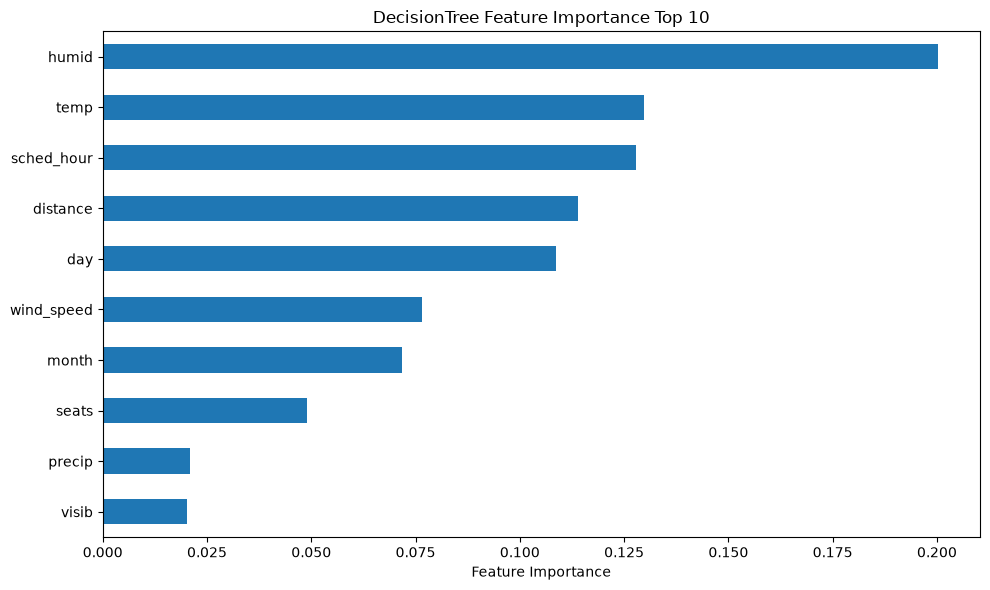

XGBoost 최적 파라미터: {'learning_rate': 0.1, 'max_depth': 9, 'n_estimators': 300}
XGBoost F1 score: 0.4035532994923858
XGBoost Accuracy: 0.859


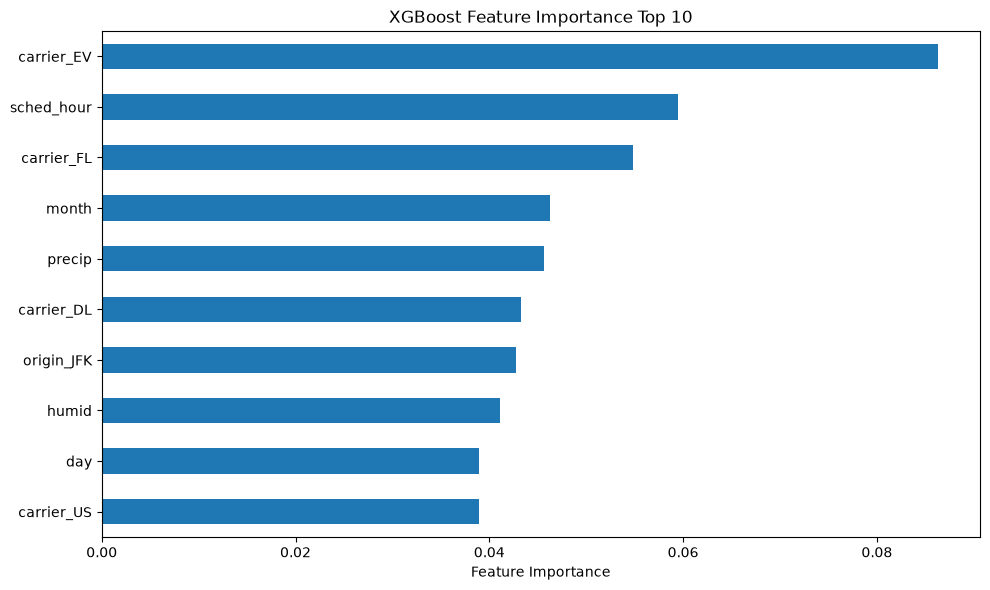

In [1]:
# 코드_공유.py
# 작업자 A, B, Admin 이 함께 사용하는 파일입니다.

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV

# 2013년 뉴욕 출발 항공편 표본 50,000건입니다.
# 항공편 정보에 기상 정보와 기체 정보를 미리 결합해 두었습니다.
df = pd.read_csv('flights_ml.csv')

NUM = ['month', 'day', 'sched_hour', 'distance', 'temp', 'humid',
       'wind_speed', 'precip', 'visib', 'seats', 'engines']
CAT = ['carrier', 'origin']

X = pd.get_dummies(df[NUM + CAT], columns=CAT)
X = X.fillna(X.median(numeric_only=True))
y = df['is_delayed']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)


####### A 작업자 작업 수행 #######

''' 코드 작성 바랍니다 '''

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, accuracy_score

# 1. DecisionTree 하이퍼파라미터 후보 설정
dt_param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15],
    'min_samples_leaf': [1, 5, 20]
}

# 2. GridSearchCV로 최적 하이퍼파라미터 탐색
dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

# 3. 최적 파라미터 및 성능 확인
dt_model = dt_grid.best_estimator_
dt_pred = dt_model.predict(X_test)

print("DecisionTree 최적 파라미터:", dt_grid.best_params_)
print("DecisionTree F1 score:", f1_score(y_test, dt_pred))
print("DecisionTree Accuracy:", accuracy_score(y_test, dt_pred))

# 4. Feature Importance 상위 10개 시각화
dt_importance = pd.Series(
    dt_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
dt_importance.sort_values().plot(kind='barh')
plt.title('DecisionTree Feature Importance Top 10')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()

####### B 작업자 작업 수행 #######

''' 코드 작성 바랍니다 '''

from xgboost import XGBClassifier

# 1. XGBoost 하이퍼파라미터 후보 설정
xgb_param_grid = {
    'max_depth': [3, 6, 9],
    'n_estimators': [100, 300],
    'learning_rate': [0.1, 0.05]
}

# 2. GridSearchCV로 최적 하이퍼파라미터 탐색
xgb_grid = GridSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        n_jobs=1
    ),
    param_grid=xgb_param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

# 3. 최적 파라미터 및 성능 확인
xgb_model = xgb_grid.best_estimator_
xgb_pred = xgb_model.predict(X_test)

print("XGBoost 최적 파라미터:", xgb_grid.best_params_)
print("XGBoost F1 score:", f1_score(y_test, xgb_pred))
print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))

# 4. Feature Importance 상위 10개 시각화
xgb_importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
xgb_importance.sort_values().plot(kind='barh')
plt.title('XGBoost Feature Importance Top 10')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()


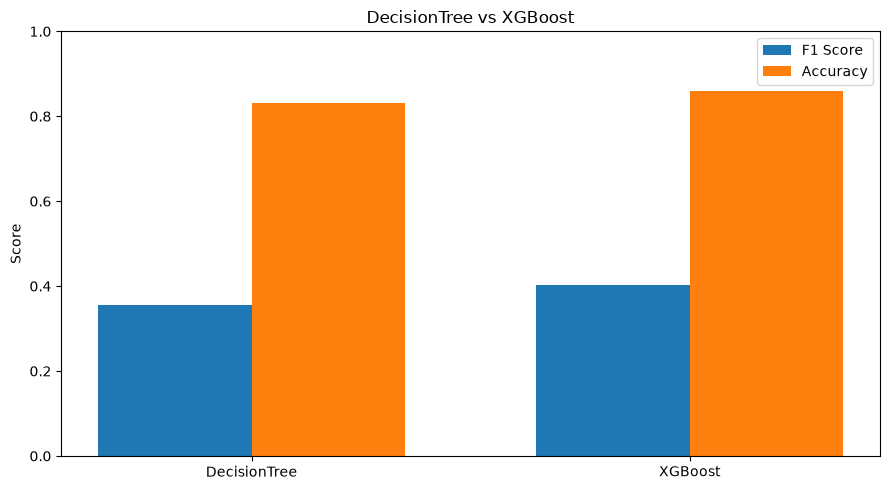

In [2]:

# DecisionTree와 XGBoost 성능 비교
model_names = ['DecisionTree', 'XGBoost']

f1_scores = [
    f1_score(y_test, dt_pred),
    f1_score(y_test, xgb_pred)
]

accuracy_scores = [
    accuracy_score(y_test, dt_pred),
    accuracy_score(y_test, xgb_pred)
]

# 성능 비교 막대그래프
x = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, f1_scores, width, label='F1 Score')
plt.bar(x + width/2, accuracy_scores, width, label='Accuracy')

plt.xticks(x, model_names)
plt.ylabel('Score')
plt.title('DecisionTree vs XGBoost')
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


In [3]:
import subprocess

print(subprocess.run(['git', 'log', '--oneline', '-n', '20'],
    capture_output=True, text=True).stdout)

7bb7d38 Merge pull request #2 from dowon-kim22/B_branch
952f45c Merge branch 'main' into B_branch
dc22a28 Update DecisionTree max_depth by Admin
21b28b7 Add XGBoost model and update max_depth
72c599f Merge pull request #1 from dowon-kim22/A_branch
99bc30e Add DecisionTree model
9d04e77 Add initial project files
7291b41 Initial commit

